In [1]:
import os
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import sklearn

if os.path.exists('/kaggle/input'):
    print("Successfully connected to Kaggle's dataset environment")
    #for root, dirs, files in os.walk('/kaggle/input'):
     #   for file in files[:5]: 
      #      print(os.path.join(root, file))
else:
    print("Not connected, code running locally")


Successfully connected to Kaggle's dataset environment


## Ecg Subset

In [2]:
#ecg data
#?? understand folder structure

'''
ecg_path = '/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/001/sensor_data'
ecg1 = pd.read_csv(ecg_path + '/2014_10_01-10_09_39/2014_10_01-10_09_39_ECG.csv')
ecg2 = pd.read_csv(ecg_path + '/2014_10_02-10_56_44/2014_10_02-10_56_44_ECG.csv')
ecg3 = pd.read_csv(ecg_path + '/2014_10_03-06_36_24/2014_10_03-06_36_24_ECG.csv')
ecg4 = pd.read_csv(ecg_path + '/2014_10_04-06_34_57/2014_10_04-06_34_57_ECG.csv')

ecg_data = pd.concat([ecg1, ecg2, ecg3, ecg4])
ecg_data['Time'] = pd.to_datetime(ecg_data['Time'])
ecg_data.sort_values(by='Time', inplace=True)
ecg_data
'''

#ecg data day 1
ecg_path = '/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/001/sensor_data'
ecg1 = pd.read_csv(ecg_path + '/2014_10_01-10_09_39/2014_10_01-10_09_39_ECG.csv')

In [3]:
ecg1.head()

,Time,EcgWaveform
0,01/10/2014 10:09:39.417,297
1,01/10/2014 10:09:39.421,297
2,01/10/2014 10:09:39.425,297
3,01/10/2014 10:09:39.429,297
4,01/10/2014 10:09:39.433,297


## Food, Glucose, Insulin Subset

In [4]:
#food, glucose, and insulin data
food_data = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/001/food.csv')
glucose_data = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/001/glucose.csv')
insulin_data = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/001/insulin.csv')

In [5]:
food_data

,picture,description,calories,balance,quality,datetime
0,001.jpg,Iceberg lettuce with olive oil and vinegar,357,Unbalance,Good quality,2014:10:01 19:27:49
1,002.jpg,"Tuna salade with boiled egg, asiago cheese an...",866,Unbalance,Good quality,2014:10:01 19:32:00
2,003.jpg,Asiago cheese,190,Unbalance,Good quality,2014:10:01 19:43:59
3,004.jpg,"Lemon yogurt, asiago cheese and bread with kiwi",1063,Balance,Good quality,2014:10:02 10:11:16
4,005.jpg,Tomatoes with cheese and bread,979,Unbalance,Good quality,2014:10:02 19:34:03
5,006.jpg,Tomatoes,42,Unbalance,Good quality,2014:10:02 19:44:51
6,007.jpg,White bread,262,Unbalance,Low quality,2014:10:03 10:08:48
7,008.jpg,Lettuce of tomatoes and carrots salad with oli...,130,Unbalance,Good quality,2014:10:03 12:37:00
8,009.jpg,Steak tartar and frites potatoes,607,Unbalance,Medium quality,2014:10:03 12:59:00
9,010.jpg,Baguette,244,Unbalance,Low quality,2014:10:03 12:59:04


In [6]:
insulin_data

,date,time,fast_insulin,slow_insulin,comment
0,2014-10-01,10:06:00,7,NaN,NaN
1,2014-10-01,16:50:00,4,NaN,NaN
2,2014-10-01,19:28:00,6,NaN,NaN
3,2014-10-01,22:27:00,8,NaN,NaN
4,2014-10-01,23:48:00,0,31.0,NaN
5,2014-10-02,00:45:00,2,NaN,NaN
6,2014-10-02,10:10:00,3,NaN,NaN
7,2014-10-02,12:34:00,12,NaN,NaN
8,2014-10-02,21:24:00,5,NaN,NaN
9,2014-10-02,22:24:00,4,31.0,NaN


## Accelerometer Subset

In [10]:
# acclerometer, heart rate, breathing rate, and activity data
sum1 = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_sensor_data/diabetes_subset_sensor_data/001/sensor_data/2014_10_01-10_09_39/2014_10_01-10_09_39_Summary.csv')

sum2 = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_sensor_data/diabetes_subset_sensor_data/001/sensor_data/2014_10_02-10_56_44/2014_10_02-10_56_44_Summary.csv')
sum3 = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_sensor_data/diabetes_subset_sensor_data/001/sensor_data/2014_10_03-06_36_24/2014_10_03-06_36_24_Summary.csv')
sum4 = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_sensor_data/diabetes_subset_sensor_data/001/sensor_data/2014_10_04-06_34_57/2014_10_04-06_34_57_Summary.csv')

summary = pd.concat([sum1, sum2, sum3, sum4])

summary['Time'] = pd.to_datetime(summary['Time'], format='%m/%d/%Y %H:%M:%S.%f')

summary['Time'] = summary['Time'].apply(lambda x: x.replace(month=x.day, day=x.month))
summary.sort_values(by='Time', inplace=True)

summary


,Time,HR,BR,SkinTemp,Posture,Activity,PeakAccel,BatteryVolts,BatteryLevel,BRAmplitude,...,SagittalPeak,DeviceTemp,StatusInfo,LinkQuality,RSSI,TxPower,CoreTemp,AuxADC1,AuxADC2,AuxADC3
0,2014-10-01 10:09:39.417,65,8.1,-3276.8,19,0.41,0.84,4.161,93,5973.0,...,0.39,24.9,528,255,-128,-128,6553.5,420,433,499
1,2014-10-01 10:09:40.417,65,8.1,-3276.8,9,0.51,1.03,4.161,93,5361.0,...,0.36,24.9,528,255,-128,-128,6553.5,419,428,485
2,2014-10-01 10:09:41.417,65,7.3,-3276.8,11,0.30,0.74,4.161,93,4733.0,...,0.12,24.9,528,255,-128,-128,6553.5,415,420,484
3,2014-10-01 10:09:42.417,65,7.3,-3276.8,18,0.43,0.98,4.161,93,4094.0,...,0.49,24.9,528,255,-128,-128,6553.5,415,422,484
4,2014-10-01 10:09:43.417,65,6.6,-3276.8,19,0.49,1.10,4.161,93,3566.0,...,0.44,24.9,528,255,-128,-128,6553.5,399,406,480
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25979,2014-10-04 13:47:56.423,0,18.4,-3276.8,-7,0.07,0.10,3.888,48,67.0,...,0.22,32.4,531,255,-128,-128,35.3,409,419,461
25980,2014-10-04 13:47:57.423,0,17.7,-3276.8,-7,0.07,0.08,3.888,48,60.0,...,0.12,32.4,531,255,-128,-128,35.3,414,420,483
25981,2014-10-04 13:47:58.423,0,17.7,-3276.8,-7,0.05,0.08,3.888,48,53.0,...,0.12,32.4,531,255,-128,-128,35.3,419,424,486
25982,2014-10-04 13:47:59.423,0,16.9,-3276.8,-8,0.02,0.04,3.888,48,47.0,...,0.13,32.4,531,255,-128,-128,35.3,415,421,483


In [11]:
print(summary.columns)

Index(['Time', 'HR', 'BR', 'SkinTemp', 'Posture', 'Activity', 'PeakAccel',
       'BatteryVolts', 'BatteryLevel', 'BRAmplitude', 'BRNoise',
       'BRConfidence', 'ECGAmplitude', 'ECGNoise', 'HRConfidence', 'HRV',
       'SystemConfidence', 'GSR', 'ROGState', 'ROGTime', 'VerticalMin',
       'VerticalPeak', 'LateralMin', 'LateralPeak', 'SagittalMin',
       'SagittalPeak', 'DeviceTemp', 'StatusInfo', 'LinkQuality', 'RSSI',
       'TxPower', 'CoreTemp', 'AuxADC1', 'AuxADC2', 'AuxADC3'],
      dtype='object')


In [15]:
# split into different categories

#physilogical / vital
phys_state = summary[['Time','HR', 'BR', 'HRV', 'CoreTemp', 'SkinTemp', 'GSR']]

#movement / activity
activity = summary[['Time','Activity', 'Posture', 'PeakAccel', 'VerticalMin', 'VerticalPeak',
                    'LateralMin', 'LateralPeak', 'SagittalMin', 'SagittalPeak'
                    ]]

#ECG / heart signal quality
ecg_quality = summary[['Time','ECGAmplitude', 'ECGNoise', 'HRConfidence']]

#breathing signal quality
breathing = summary[['Time','BRAmplitude', 'BRNoise', 'BRConfidence']]

#overall data quality and time
sum_data = summary[['Time', 'SystemConfidence']]

#device hardware
device = summary[['Time','BatteryVolts', 'BatteryLevel', 'DeviceTemp', 'StatusInfo']]

#wireless/communication
comm = summary[['Time','LinkQuality', 'RSSI', 'TxPower']]

#system/receiver
rog = summary[['Time','ROGState', 'ROGTime']]

#auxiliary sensor inputs
aux = summary[['Time','AuxADC1', 'AuxADC2', 'AuxADC3']]


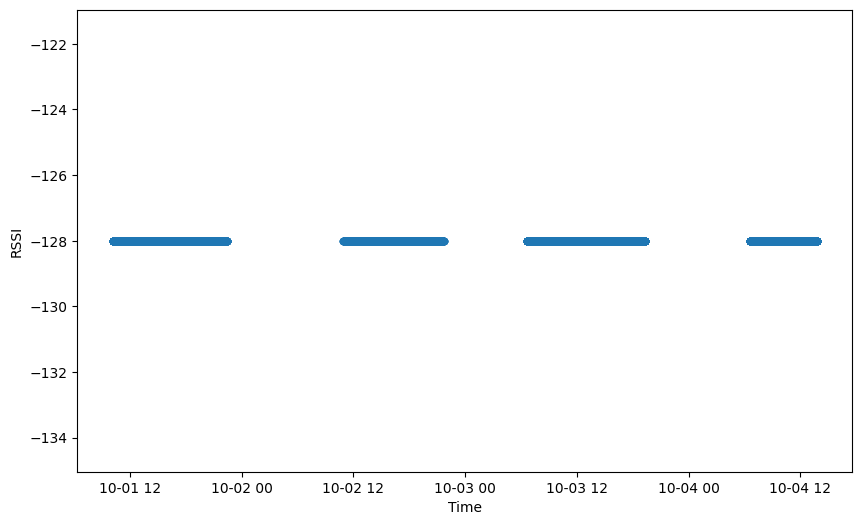

In [29]:
#visualize data
def graph(df, col):
    df.plot(x = 'Time', y=col, figsize=(10,6), kind='scatter')

graph(summary, 'RSSI')

In [24]:
phys_state.describe()

,Time,HR,BR,HRV,CoreTemp,SkinTemp,GSR
count,154486,154486.000000,154486.000000,154486.000000,154486.000000,1.544860e+05,154486.0
mean,2014-10-02 22:37:58.661618176,47.788783,18.520966,59169.391401,45.852622,-3.276800e+03,65535.0
min,2014-10-01 10:09:39.417000,0.000000,0.000000,26.000000,35.100000,-3.276800e+03,65535.0
25%,2014-10-01 20:53:20.666999808,0.000000,12.200000,65535.000000,35.500000,-3.276800e+03,65535.0
50%,2014-10-02 20:10:19.920000,60.000000,16.200000,65535.000000,36.300000,-3.276800e+03,65535.0
75%,2014-10-03 15:49:21.170999808,82.000000,20.600000,65535.000000,37.300000,-3.276800e+03,65535.0
max,2014-10-04 13:48:00.423000,240.000000,6553.500000,65535.000000,6553.500000,-3.276800e+03,65535.0
std,NaN,45.334390,106.695037,19397.268242,247.983537,8.202305e-09,0.0


In [25]:
activity.describe()

,Time,Activity,Posture,PeakAccel,VerticalMin,VerticalPeak,LateralMin,LateralPeak,SagittalMin,SagittalPeak
count,154486,154486.000000,154486.000000,154486.000000,154486.000000,154486.000000,154486.000000,154486.000000,154486.000000,154486.000000
mean,2014-10-02 22:37:58.661618176,0.062966,-11.182657,0.136507,-1.017679,-0.855214,-0.227317,-0.087082,0.086625,0.247677
min,2014-10-01 10:09:39.417000,0.000000,-124.000000,0.010000,-10.510000,-1.000000,-8.420000,-0.900000,-7.810000,-0.920000
25%,2014-10-01 20:53:20.666999808,0.010000,-22.000000,0.040000,-1.060000,-0.960000,-0.360000,-0.240000,-0.080000,0.080000
50%,2014-10-02 20:10:19.920000,0.020000,-15.000000,0.060000,-1.020000,-0.920000,-0.250000,-0.090000,0.060000,0.220000
75%,2014-10-03 15:49:21.170999808,0.070000,-9.000000,0.140000,-0.960000,-0.810000,-0.060000,0.040000,0.320000,0.440000
max,2014-10-04 13:48:00.423000,1.480000,124.000000,7.550000,0.500000,4.280000,0.840000,2.970000,0.800000,3.460000
std,NaN,0.096721,22.217143,0.198126,0.205874,0.165120,0.238606,0.201999,0.324518,0.270435


In [27]:
ecg_quality.describe()

,Time,ECGAmplitude,ECGNoise,HRConfidence
count,154486,154486.000000,154486.000000,154486.000000
mean,2014-10-02 22:37:58.661618176,0.001207,0.000329,23.814126
min,2014-10-01 10:09:39.417000,0.000000,0.000000,0.000000
25%,2014-10-01 20:53:20.666999808,0.000800,0.000060,1.000000
50%,2014-10-02 20:10:19.920000,0.000800,0.000140,1.000000
75%,2014-10-03 15:49:21.170999808,0.001420,0.000320,37.000000
max,2014-10-04 13:48:00.423000,0.059480,0.021320,100.000000
std,NaN,0.001332,0.000624,36.096549
